In [ ]:
import os
os.chdir('..')

In [ ]:
import pandas as pd
mcc = pd.read_csv('./results/PPI/MCC_top_10.csv')
betweenness = pd.read_csv('./results/PPI/Betweenness_top_10.csv')
print(mcc.head())
print(betweenness.head())

In [ ]:
hub_network_annotations = pd.read_csv('./results/PPI/hub_network_annotations.tsv', sep='\t')

ensp_to_gene = dict(zip(
    hub_network_annotations['identifier'].str.replace('9606.', '', regex=False),
    hub_network_annotations['#node']
))

mcc_ids = [id.replace('9606.', '') for id in mcc['Name'].tolist()]
betweenness_ids = [id.replace('9606.', '') for id in betweenness['Name'].tolist()]

mcc_genes = [ensp_to_gene.get(id, id) for id in mcc_ids]
betweenness_genes = [ensp_to_gene.get(id, id) for id in betweenness_ids]

print(f"MCC genes: {mcc_genes}")
print(f"Betweenness genes: {betweenness_genes}")
print(f"Overlap: {set(mcc_genes) & set(betweenness_genes)}")

In [ ]:
consensus_df = pd.read_csv('./results/DEG/consensus_DEGs.csv')
hub_directions = consensus_df.set_index('Gene')['direction'].to_dict()

In [22]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

# Load edges
edges_df = pd.read_csv('./results/PPI/hub_network_edges.tsv', sep='\t')
print(edges_df.columns.tolist())
print(edges_df.head())

# Load degrees
degrees_df = pd.read_csv('./results/PPI/hub_network_degrees.tsv', sep='\t')
print(degrees_df.columns.tolist())
print(degrees_df.head())

['#node1', 'node2', 'node1_string_id', 'node2_string_id', 'neighborhood_on_chromosome', 'gene_fusion', 'phylogenetic_cooccurrence', 'homology', 'coexpression', 'experimentally_determined_interaction', 'database_annotated', 'automated_textmining', 'combined_score']
  #node1   node2       node1_string_id       node2_string_id  \
0   ASPM  DLGAP5  9606.ENSP00000356379  9606.ENSP00000247191   
1   ASPM   KIF11  9606.ENSP00000356379  9606.ENSP00000260731   
2   ASPM   BUB1B  9606.ENSP00000356379  9606.ENSP00000287598   
3   ASPM    TPX2  9606.ENSP00000356379  9606.ENSP00000300403   
4   ASPM    BUB1  9606.ENSP00000356379  9606.ENSP00000302530   

   neighborhood_on_chromosome  gene_fusion  phylogenetic_cooccurrence  \
0                           0          0.0                          0   
1                           0          0.0                          0   
2                           0          0.0                          0   
3                           0          0.0                

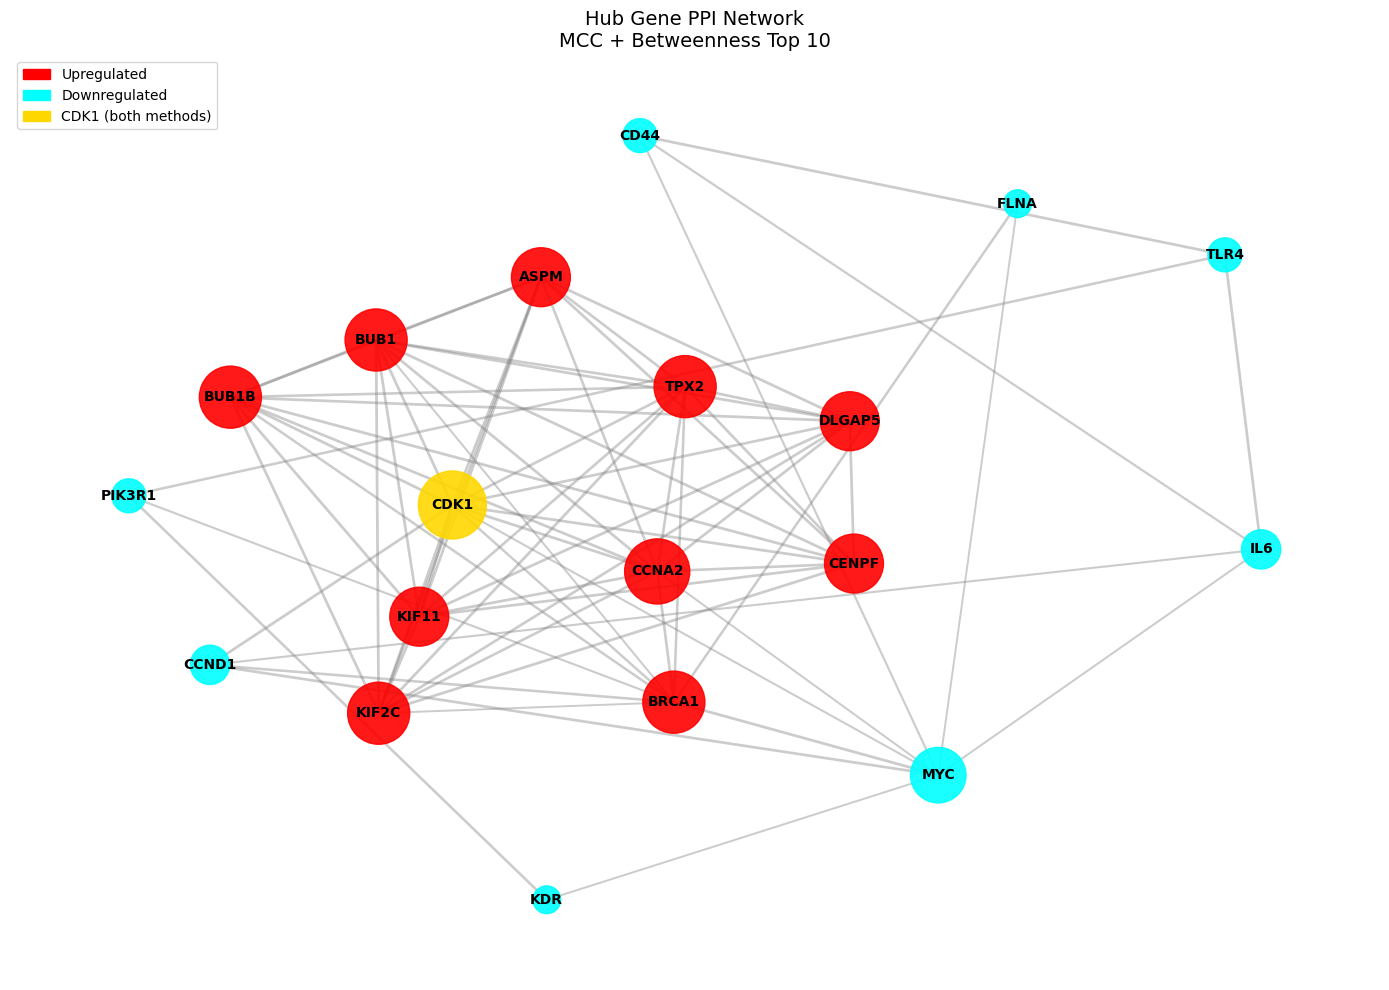

In [30]:
# Build network
G = nx.Graph()

# Add edges
for _, row in edges_df.iterrows():
    G.add_edge(row['#node1'], row['node2'], weight=row['combined_score'])

both = set(mcc_genes) & set(betweenness_genes)

# Node colors
color_map = []
for node in G.nodes():
    if node in both:
        color_map.append('gold')
    elif hub_directions.get(node, 'Down') == 'Up':
        color_map.append('red')
    else:
        color_map.append('cyan')

# Node sizes by degree
node_sizes = [degrees_df[degrees_df['#node'] == node]['node_degree'].values[0] * 200 
              for node in G.nodes()]

# Edge weights
edge_weights = [G[u][v]['weight'] * 2 for u, v in G.edges()]

# Plot
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42, k=2)

nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=node_sizes, alpha=0.9)
nx.draw_networkx_edges(G, pos, width=edge_weights, alpha=0.4, edge_color='grey')
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# Legend
legend = [mpatches.Patch(color='red', label='Upregulated'),
          mpatches.Patch(color='cyan', label='Downregulated'),
          mpatches.Patch(color='gold', label='CDK1 (both methods)')]
plt.legend(handles=legend, loc='upper left')

plt.title('Hub Gene PPI Network\nMCC + Betweenness Top 10', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('./figures/hub_gene_network.png', dpi=300)
plt.show()